# Analisis Eksploratif Performa Siswa | Tugas Minggu 4

**Divisi Data Analyst - Vinix7 - Kelompok 36**

Fokus analisis:
- Profil statistik
- Eksplorasi visual
- Tiga insight dan hipotesis
- Rekomendasi awal untuk intervensi akademik
- Evaluasi model prediksi sebagai analisis tambahan


## 1. Persiapan


In [ ]:

# Library untuk manipulasi data
import os
import io
import textwrap
import warnings
import numpy as np
import pandas as pd

# Library untuk visualisasi
import matplotlib.pyplot as plt
import seaborn as sns

warnings.filterwarnings("ignore")
sns.set_style("whitegrid")

# Folder untuk menyimpan grafik yang nanti dimasukkan ke Technical Report
OUTPUT_DIR = "week4_outputs"
os.makedirs(OUTPUT_DIR, exist_ok=True)

print("Persiapan selesai.")


Persiapan selesai.


## 2. Unggah Dataset CSV


In [ ]:

# Upload CSV dari komputer
try:
    from google.colab import files
    uploaded = files.upload()

    csv_name = next(iter(uploaded))
    dataset = pd.read_csv(io.BytesIO(uploaded[csv_name]))
    print(f"Dataset berhasil dibaca: {csv_name}")
except ImportError:
    # Fallback jika notebook dijalankan di Jupyter lokal
    csv_name = input("Masukkan path file CSV: ").strip()
    dataset = pd.read_csv(csv_name)

print("Ukuran dataset:", dataset.shape)
dataset.head()


Saving Student_Performance.csv to Student_Performance.csv
Dataset berhasil dibaca: Student_Performance.csv
Ukuran dataset: (10000, 6)


,Hours Studied,Previous Scores,Extracurricular Activities,Sleep Hours,Sample Question Papers Practiced,Performance Index
0,7,99,Yes,9,1,91.0
1,4,82,No,4,2,65.0
2,8,51,Yes,7,2,45.0
3,5,52,Yes,5,2,36.0
4,7,75,No,8,5,66.0


## 3. Struktur dan Kualitas Data

Pemeriksaan awal mencakup:
- ukuran dataset dan tipe data;
- nilai kosong dan baris identik;
- kesesuaian rentang nilai setiap variabel.


In [ ]:

print("INFO DATASET")
dataset.info()

print("\n5 BARIS PERTAMA")
display(dataset.head())

print("\n5 BARIS TERAKHIR")
display(dataset.tail())


INFO DATASET
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 10000 entries, 0 to 9999
Data columns (total 6 columns):
 #   Column                            Non-Null Count  Dtype  
---  ------                            --------------  -----  
 0   Hours Studied                     10000 non-null  int64  
 1   Previous Scores                   10000 non-null  int64  
 2   Extracurricular Activities        10000 non-null  object 
 3   Sleep Hours                       10000 non-null  int64  
 4   Sample Question Papers Practiced  10000 non-null  int64  
 5   Performance Index                 10000 non-null  float64
dtypes: float64(1), int64(4), object(1)
memory usage: 468.9+ KB

5 BARIS PERTAMA


,Hours Studied,Previous Scores,Extracurricular Activities,Sleep Hours,Sample Question Papers Practiced,Performance Index
0,7,99,Yes,9,1,91.0
1,4,82,No,4,2,65.0
2,8,51,Yes,7,2,45.0
3,5,52,Yes,5,2,36.0
4,7,75,No,8,5,66.0



5 BARIS TERAKHIR


,Hours Studied,Previous Scores,Extracurricular Activities,Sleep Hours,Sample Question Papers Practiced,Performance Index
9995,1,49,Yes,4,2,23.0
9996,7,64,Yes,8,5,58.0
9997,6,83,Yes,8,5,74.0
9998,9,97,Yes,7,0,95.0
9999,7,74,No,8,1,64.0


In [ ]:

# Pemeriksaan kualitas data
missing_summary = dataset.isna().sum().to_frame("Missing")
missing_summary["Missing (%)"] = (missing_summary["Missing"] / len(dataset) * 100).round(2)

duplicate_count = dataset.duplicated().sum()

print("NILAI KOSONG")
display(missing_summary)

print(f"Jumlah exact duplicate rows: {duplicate_count}")
print(f"Persentase exact duplicate : {duplicate_count / len(dataset) * 100:.2f}%")

# Validasi rentang berdasarkan definisi fitur pada dataset
range_checks = {
    "Hours Studied": dataset["Hours Studied"].between(1, 9).all(),
    "Previous Scores": dataset["Previous Scores"].between(40, 99).all(),
    "Sleep Hours": dataset["Sleep Hours"].between(4, 9).all(),
    "Sample Question Papers Practiced": dataset["Sample Question Papers Practiced"].between(0, 9).all(),
    "Performance Index": dataset["Performance Index"].between(10, 100).all()
}

print("\nRANGE CHECK")
for col, status in range_checks.items():
    print(f"{col:35s}: {'OK' if status else 'PERLU REVIEW'}")

print("\nKeputusan analisis:")
print("- EDA menggunakan seluruh catatan yang tersedia.")
print("- Baris identik belum dapat dipastikan sebagai kesalahan pencatatan tanpa identitas siswa.")
print("- Evaluasi model menghapus baris identik sebelum membagi data latih dan uji.")


NILAI KOSONG


,Missing,Missing (%)
Hours Studied,0,0.0
Previous Scores,0,0.0
Extracurricular Activities,0,0.0
Sleep Hours,0,0.0
Sample Question Papers Practiced,0,0.0
Performance Index,0,0.0


Jumlah exact duplicate rows: 127
Persentase exact duplicate : 1.27%

RANGE CHECK
Hours Studied                      : OK
Previous Scores                    : OK
Sleep Hours                        : OK
Sample Question Papers Practiced   : OK
Performance Index                  : OK

Keputusan analisis:
- EDA menggunakan seluruh catatan yang tersedia.
- Baris identik belum dapat dipastikan sebagai kesalahan pencatatan tanpa identitas siswa.
- Evaluasi model menghapus baris identik sebelum membagi data latih dan uji.


### Hasil Pemeriksaan Kualitas Data

Dataset memuat **10.000 catatan**, tanpa nilai kosong. Terdapat **127 baris identik (1,27%)**. Tanpa identitas siswa, baris identik belum dapat dipastikan sebagai kesalahan pencatatan.

Seluruh catatan digunakan untuk EDA. Pada evaluasi model, baris identik dihapus sebelum pembagian data latih dan uji untuk mengurangi peluang profil yang sama muncul di kedua kelompok.


## 4. Profil Statistik

- **Numerik:** mean, median, modus, simpangan baku, minimum, maksimum.
- **Kategorikal:** jumlah kategori, modus, frekuensi, dan proporsi.


In [ ]:

# Kolom numerik
numeric_cols = dataset.select_dtypes(include=np.number).columns.tolist()

numeric_profile = pd.DataFrame({
    "Mean": dataset[numeric_cols].mean(),
    "Median": dataset[numeric_cols].median(),
    "Mode": [dataset[col].mode().iloc[0] for col in numeric_cols],
    "Std Dev": dataset[numeric_cols].std(),
    "Minimum": dataset[numeric_cols].min(),
    "Maximum": dataset[numeric_cols].max()
}).round(2)

print("STATISTICAL PROFILING - NUMERIK")
display(numeric_profile)


STATISTICAL PROFILING - NUMERIK


,Mean,Median,Mode,Std Dev,Minimum,Maximum
Hours Studied,4.99,5.0,1.0,2.59,1.0,9.0
Previous Scores,69.45,69.0,54.0,17.34,40.0,99.0
Sleep Hours,6.53,7.0,8.0,1.70,4.0,9.0
Sample Question Papers Practiced,4.58,5.0,6.0,2.87,0.0,9.0
Performance Index,55.22,55.0,67.0,19.21,10.0,100.0


In [ ]:

# Kolom kategorikal
categorical_cols = dataset.select_dtypes(include="object").columns.tolist()

categorical_rows = []
for col in categorical_cols:
    vc = dataset[col].value_counts()
    categorical_rows.append({
        "Column": col,
        "Unique Categories": dataset[col].nunique(),
        "Mode": dataset[col].mode().iloc[0],
        "Mode Frequency": int(vc.iloc[0]),
        "Mode Proportion (%)": round(vc.iloc[0] / len(dataset) * 100, 2)
    })

categorical_profile = pd.DataFrame(categorical_rows)

print("STATISTICAL PROFILING - KATEGORIKAL")
display(categorical_profile)

print("\nDistribusi Extracurricular Activities:")
display(
    dataset["Extracurricular Activities"]
    .value_counts()
    .rename_axis("Category")
    .to_frame("Count")
    .assign(Proportion=lambda x: (x["Count"] / len(dataset) * 100).round(2))
)


STATISTICAL PROFILING - KATEGORIKAL


,Column,Unique Categories,Mode,Mode Frequency,Mode Proportion (%)
0,Extracurricular Activities,2,No,5052,50.52



Distribusi Extracurricular Activities:


,Count,Proportion
Category,,
No,5052,50.52
Yes,4948,49.48


In [ ]:

# Ringkasan statistik
perf_mean = dataset["Performance Index"].mean()
perf_median = dataset["Performance Index"].median()
perf_std = dataset["Performance Index"].std()

prev_mean = dataset["Previous Scores"].mean()
hours_mean = dataset["Hours Studied"].mean()
sleep_mean = dataset["Sleep Hours"].mean()
paper_mean = dataset["Sample Question Papers Practiced"].mean()

print("RINGKASAN STATISTIK")
print(
    f"1. Performance Index: rata-rata {perf_mean:.2f}, median {perf_median:.2f}, "
    f"simpangan baku {perf_std:.2f}. Sebaran nilai antarsiswa cukup besar."
)
print(
    f"2. Previous Scores: rata-rata {prev_mean:.2f}. Hubungannya dengan Performance Index "
    "ditelaah pada analisis korelasi."
)
print(
    f"3. Hours Studied: rata-rata {hours_mean:.2f} jam; Sleep Hours: {sleep_mean:.2f} jam; "
    f"latihan soal: {paper_mean:.2f}. Hubungan masing-masing dengan target diperiksa berikutnya."
)
print(
    "4. Extracurricular Activities: kategori Yes dan No memiliki jumlah yang hampir seimbang."
)


RINGKASAN STATISTIK
1. Performance Index: rata-rata 55.22, median 55.00, simpangan baku 19.21. Sebaran nilai antarsiswa cukup besar.
2. Previous Scores: rata-rata 69.45. Hubungannya dengan Performance Index ditelaah pada analisis korelasi.
3. Hours Studied: rata-rata 4.99 jam; Sleep Hours: 6.53 jam; latihan soal: 4.58. Hubungan masing-masing dengan target diperiksa berikutnya.
4. Extracurricular Activities: kategori Yes dan No memiliki jumlah yang hampir seimbang.


## 5. Eksplorasi Visual


### 5.1 Distribusi Performance Index

**Pertanyaan:** Bagaimana sebaran nilai Performance Index?


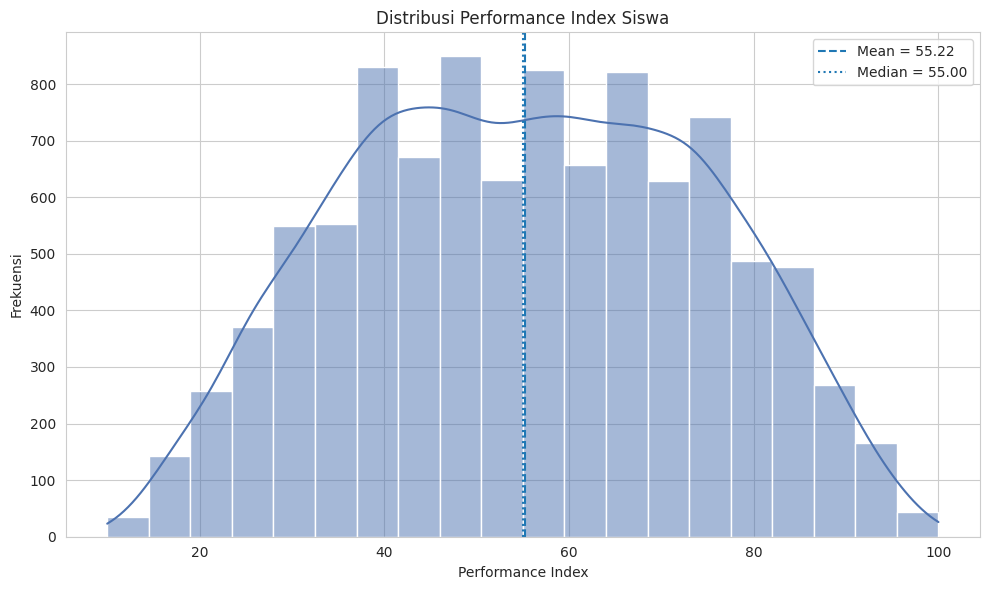

In [ ]:

plt.figure(figsize=(10, 6))
sns.histplot(dataset["Performance Index"], bins=20, kde=True, color="#4C72B0")
plt.axvline(dataset["Performance Index"].mean(), linestyle="--", label=f"Mean = {dataset['Performance Index'].mean():.2f}")
plt.axvline(dataset["Performance Index"].median(), linestyle=":", label=f"Median = {dataset['Performance Index'].median():.2f}")
plt.title("Distribusi Performance Index Siswa")
plt.xlabel("Performance Index")
plt.ylabel("Frekuensi")
plt.legend()
plt.tight_layout()

target_plot = os.path.join(OUTPUT_DIR, "01_distribution_performance.png")
plt.savefig(target_plot, dpi=180, bbox_inches="tight")
plt.show()


**Temuan:** Performance Index berkisar dari **10 hingga 100**. Rata-rata **55,22** dan median **55** menunjukkan pusat distribusi yang relatif seimbang; simpangan baku **19,21** menunjukkan perbedaan antarsiswa yang cukup besar. Rata-rata saja belum mewakili seluruh variasi performa.


### 5.2 Korelasi Variabel Numerik

**Pertanyaan:** Variabel numerik mana yang paling kuat berkaitan dengan Performance Index?


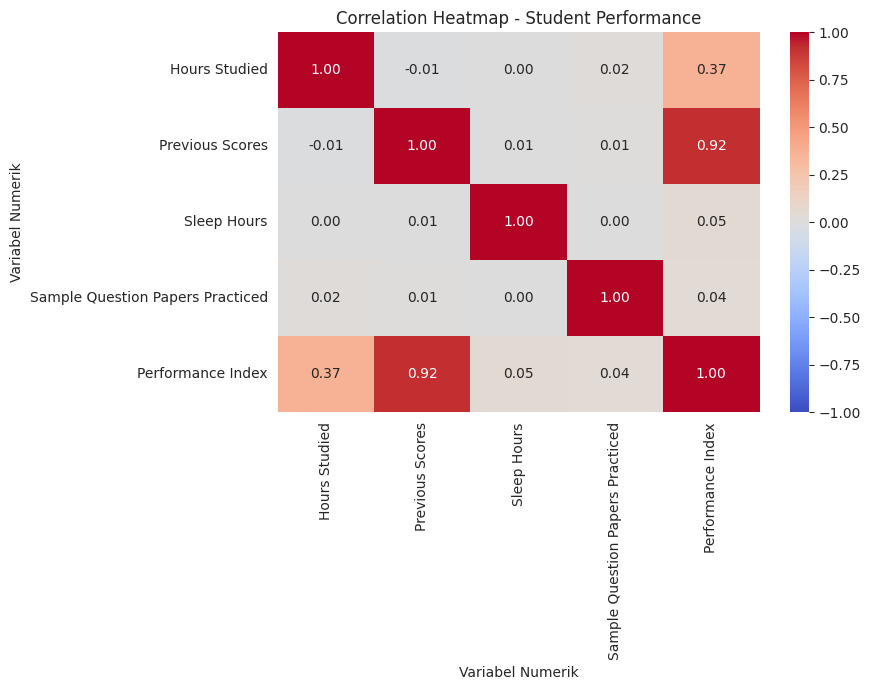

Korelasi terhadap Performance Index:


,Correlation
Performance Index,1.000000
Previous Scores,0.915189
Hours Studied,0.373730
Sleep Hours,0.048106
Sample Question Papers Practiced,0.043268


In [ ]:

corr_matrix = dataset[numeric_cols].corr()

plt.figure(figsize=(9, 7))
sns.heatmap(corr_matrix, annot=True, fmt=".2f", cmap="coolwarm", vmin=-1, vmax=1)
plt.title("Correlation Heatmap - Student Performance")
plt.xlabel("Variabel Numerik")
plt.ylabel("Variabel Numerik")
plt.tight_layout()

corr_plot = os.path.join(OUTPUT_DIR, "02_correlation_heatmap.png")
plt.savefig(corr_plot, dpi=180, bbox_inches="tight")
plt.show()

target_corr = corr_matrix["Performance Index"].sort_values(ascending=False)
print("Korelasi terhadap Performance Index:")
display(target_corr.to_frame("Correlation"))


## 6. Tiga Insight Utama dan Hipotesis

Setiap temuan didukung hasil statistik dan visualisasi. Hipotesis berikut merupakan dasar pengujian lanjutan.


### Insight 1 - Previous Scores paling kuat berkaitan dengan Performance Index

**Pertanyaan:** Seberapa kuat hubungan nilai sebelumnya dengan performa saat ini?


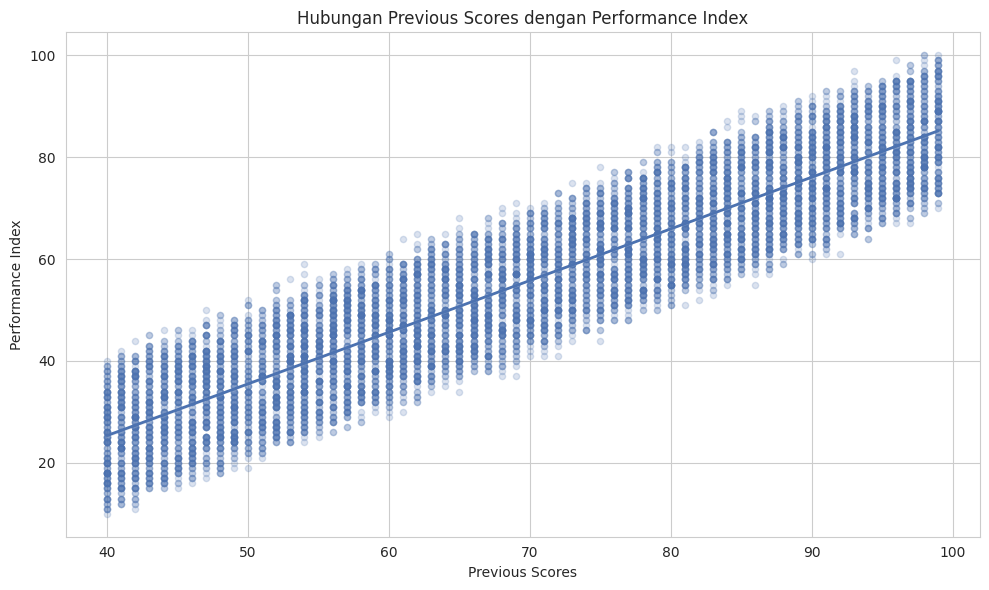

Correlation Previous Scores vs Performance Index = 0.915


In [ ]:

prev_corr = dataset["Previous Scores"].corr(dataset["Performance Index"])

plt.figure(figsize=(10, 6))
sns.regplot(
    data=dataset,
    x="Previous Scores",
    y="Performance Index",
    scatter_kws={"alpha": 0.20, "s": 20},
    line_kws={"linewidth": 2},
    color="#4C72B0"
)
plt.title("Hubungan Previous Scores dengan Performance Index")
plt.xlabel("Previous Scores")
plt.ylabel("Performance Index")
plt.tight_layout()

prev_plot = os.path.join(OUTPUT_DIR, "03_previous_scores_vs_performance.png")
plt.savefig(prev_plot, dpi=180, bbox_inches="tight")
plt.show()

print(f"Correlation Previous Scores vs Performance Index = {prev_corr:.3f}")


**Temuan:** Previous Scores memiliki korelasi positif **0,915** dengan Performance Index, tertinggi di antara variabel numerik yang dianalisis. Grafik sebar menunjukkan pola yang konsisten: siswa dengan nilai sebelumnya lebih tinggi cenderung memperoleh Performance Index lebih tinggi.

**Hipotesis:** Siswa dengan nilai sebelumnya rendah berpeluang membutuhkan penguatan materi dasar. Previous Scores dapat diuji sebagai dasar penyaringan awal untuk menentukan prioritas remedial.

> Hubungan ini bersifat korelasional; hasil EDA belum membuktikan penyebabnya.


### Insight 2 - Jam belajar berkaitan dengan performa pada setiap kelompok nilai awal

**Pertanyaan:** Apakah pola hubungan jam belajar dan performa tetap terlihat setelah siswa dikelompokkan menurut Previous Scores?


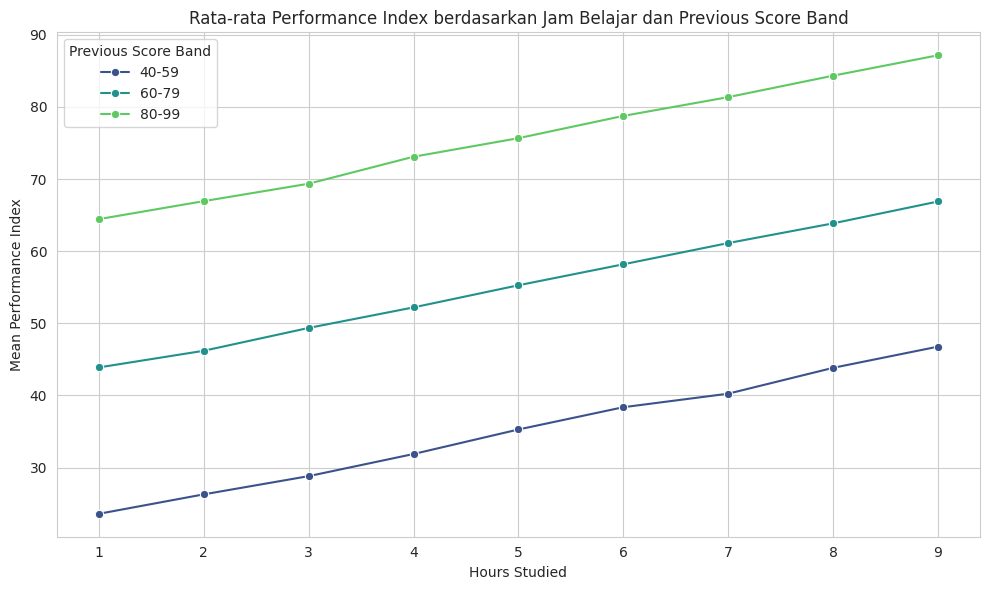

,Previous Score Band,Hours Studied,Performance Index
0,40-59,1,23.591371
1,40-59,2,26.286517
2,40-59,3,28.812139
3,40-59,4,31.880886
4,40-59,5,35.279778
5,40-59,6,38.367021
6,40-59,7,40.243655
7,40-59,8,43.826923
8,40-59,9,46.766110
9,60-79,1,43.882022


In [ ]:

# Membuat band skor sebelumnya untuk analisis yang lebih mudah dibaca
dataset_eda = dataset.copy()
dataset_eda["Previous Score Band"] = pd.cut(
    dataset_eda["Previous Scores"],
    bins=[39, 59, 79, 99],
    labels=["40-59", "60-79", "80-99"],
    include_lowest=True
)

mean_by_hours = (
    dataset_eda
    .groupby(["Previous Score Band", "Hours Studied"], observed=False)["Performance Index"]
    .mean()
    .reset_index()
)

plt.figure(figsize=(10, 6))
sns.lineplot(
    data=mean_by_hours,
    x="Hours Studied",
    y="Performance Index",
    hue="Previous Score Band",
    marker="o",
    palette="viridis"
)
plt.title("Rata-rata Performance Index berdasarkan Jam Belajar dan Previous Score Band")
plt.xlabel("Hours Studied")
plt.ylabel("Mean Performance Index")
plt.legend(title="Previous Score Band")
plt.tight_layout()

hours_plot = os.path.join(OUTPUT_DIR, "04_hours_by_previous_band.png")
plt.savefig(hours_plot, dpi=180, bbox_inches="tight")
plt.show()

display(mean_by_hours.head(12))


**Temuan:** Dalam setiap kelompok Previous Scores, rata-rata Performance Index meningkat seiring bertambahnya Hours Studied. Pola ini menunjukkan bahwa jam belajar layak ditelaah sebagai sasaran program, dengan tetap mempertimbangkan perbedaan nilai awal.

**Hipotesis:** Jadwal belajar yang terstruktur, disertai dukungan akademik sesuai kemampuan awal, berpotensi memperbaiki performa.

> Analisis ini belum mengukur dampak penambahan jam belajar. Hipotesis perlu diuji dengan data dari waktu ke waktu atau eksperimen.


### Insight 3 - Jam belajar tinggi belum menghapus selisih performa antarkelompok

**Pertanyaan:** Apakah siswa dengan Previous Scores rendah dan jam belajar tinggi mencapai performa kelompok nilai awal menengah?


Rata-rata Performance Index per segmen:


Hours Group,1-3 jam,4-6 jam,7-9 jam
Previous Score Band,,,
40-59,26.11,35.22,43.67
60-79,46.57,55.31,63.87
80-99,66.86,75.84,84.27


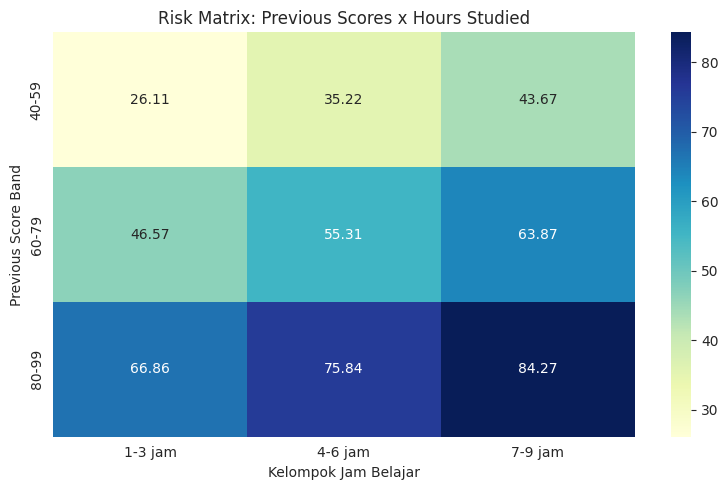

Nilai awal rendah, 1-3 jam : 26.11
Nilai awal rendah, 7-9 jam : 43.67
Nilai awal menengah, 1-3 jam: 46.57
Nilai awal tinggi, 7-9 jam : 84.27
Selisih kelompok nilai awal rendah (1-3 dan 7-9 jam): 17.56 poin


In [ ]:

dataset_eda["Hours Group"] = pd.cut(
    dataset_eda["Hours Studied"],
    bins=[0, 3, 6, 9],
    labels=["1-3 jam", "4-6 jam", "7-9 jam"],
    include_lowest=True
)

risk_matrix = dataset_eda.pivot_table(
    values="Performance Index",
    index="Previous Score Band",
    columns="Hours Group",
    aggfunc="mean",
    observed=False
).round(2)

print("Rata-rata Performance Index per segmen:")
display(risk_matrix)

plt.figure(figsize=(8, 5))
sns.heatmap(risk_matrix, annot=True, fmt=".2f", cmap="YlGnBu")
plt.title("Risk Matrix: Previous Scores x Hours Studied")
plt.xlabel("Kelompok Jam Belajar")
plt.ylabel("Previous Score Band")
plt.tight_layout()

risk_plot = os.path.join(OUTPUT_DIR, "05_risk_matrix.png")
plt.savefig(risk_plot, dpi=180, bbox_inches="tight")
plt.show()

low_low = risk_matrix.loc["40-59", "1-3 jam"]
low_high = risk_matrix.loc["40-59", "7-9 jam"]
mid_low = risk_matrix.loc["60-79", "1-3 jam"]
high_high = risk_matrix.loc["80-99", "7-9 jam"]

print(f"Nilai awal rendah, 1-3 jam : {low_low:.2f}")
print(f"Nilai awal rendah, 7-9 jam : {low_high:.2f}")
print(f"Nilai awal menengah, 1-3 jam: {mid_low:.2f}")
print(f"Nilai awal tinggi, 7-9 jam : {high_high:.2f}")
print(f"Selisih kelompok nilai awal rendah (1-3 dan 7-9 jam): {low_high - low_low:.2f} poin")


**Temuan:** Pada kelompok Previous Scores **40-59**, rata-rata Performance Index naik dari **26,11** pada 1-3 jam belajar menjadi **43,67** pada 7-9 jam: selisih **17,56 poin**. Angka **43,67** masih di bawah kelompok Previous Scores **60-79** yang belajar 1-3 jam (**46,57**).

**Hipotesis:** Bagi kelompok nilai awal rendah, program yang menggabungkan remedial konsep dan pembinaan kebiasaan belajar berpotensi lebih tepat daripada program jam belajar saja. Kelompok nilai awal menengah dengan jam belajar rendah dapat menjadi sasaran dukungan konsistensi belajar.


## 7. Ringkasan Tiga Insight

Tabel berikut merangkum bukti dan tindak lanjut untuk laporan teknis.


In [ ]:

insight_summary = pd.DataFrame({
    "Insight": [
        "Previous Scores paling kuat berkaitan dengan performa",
        "Jam belajar berkaitan dengan performa di setiap kelompok nilai awal",
        "Jam belajar tinggi belum menghapus selisih antarkelompok"
    ],
    "Bukti": [
        f"Korelasi Previous Scores dan Performance Index: {prev_corr:.3f}",
        "Rata-rata Performance Index meningkat seiring jam belajar di tiap kelompok nilai awal",
        f"Kelompok 40-59: selisih {low_high - low_low:.2f} poin antara 1-3 dan 7-9 jam; nilai akhir masih di bawah kelompok 60-79 dengan 1-3 jam"
    ],
    "Hipotesis / Tindak Lanjut": [
        "Uji penyaringan awal berdasarkan Previous Scores dan prioritas penguatan materi dasar",
        "Uji jadwal belajar terstruktur sesuai kelompok nilai awal",
        "Uji kombinasi remedial konsep dan pembinaan kebiasaan belajar"
    ]
})

display(insight_summary)


,Insight,Bukti,Hipotesis / Tindak Lanjut
0,Previous Scores paling kuat berkaitan dengan p...,Korelasi Previous Scores dan Performance Index...,Uji penyaringan awal berdasarkan Previous Scor...
1,Jam belajar berkaitan dengan performa di setia...,Rata-rata Performance Index meningkat seiring ...,Uji jadwal belajar terstruktur sesuai kelompok...
2,Jam belajar tinggi belum menghapus selisih ant...,Kelompok 40-59: selisih 17.56 poin antara 1-3 ...,Uji kombinasi remedial konsep dan pembinaan ke...


## 8. Analisis Tambahan: Model Prediksi

**Linear Regression** digunakan untuk memperkirakan Performance Index dari variabel yang tersedia. Target berupa angka kontinu dan pola pada EDA tampak mendekati linear. Koefisien model membantu menjelaskan asosiasi tiap variabel setelah variabel lain diperhitungkan.


In [ ]:

from sklearn.model_selection import train_test_split
from sklearn.compose import ColumnTransformer
from sklearn.preprocessing import OneHotEncoder
from sklearn.pipeline import Pipeline
from sklearn.linear_model import LinearRegression
from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score

# Untuk evaluasi model, exact duplicate dihapus agar tidak mudah muncul di train dan test sekaligus
dataset_model = dataset.drop_duplicates().copy()

X = dataset_model.drop(columns="Performance Index")
y = dataset_model["Performance Index"]

categorical_features = ["Extracurricular Activities"]
numeric_features = [col for col in X.columns if col not in categorical_features]

preprocessor = ColumnTransformer(
    transformers=[
        ("num", "passthrough", numeric_features),
        ("cat", OneHotEncoder(drop="first", handle_unknown="ignore"), categorical_features)
    ]
)

model = Pipeline(steps=[
    ("preprocessor", preprocessor),
    ("regressor", LinearRegression())
])

X_train, X_test, y_train, y_test = train_test_split(
    X, y,
    test_size=0.20,
    random_state=42
)

model.fit(X_train, y_train)
y_pred = model.predict(X_test)

r2 = r2_score(y_test, y_pred)
mae = mean_absolute_error(y_test, y_pred)
rmse = np.sqrt(mean_squared_error(y_test, y_pred))

print("MODEL PERFORMANCE")
print(f"Data model setelah drop exact duplicate: {len(dataset_model):,} rows")
print(f"Train rows: {len(X_train):,}")
print(f"Test rows : {len(X_test):,}")
print(f"R²        : {r2:.4f}")
print(f"MAE       : {mae:.4f}")
print(f"RMSE      : {rmse:.4f}")


MODEL PERFORMANCE
Data model setelah drop exact duplicate: 9,873 rows
Train rows: 7,898
Test rows : 1,975
R²        : 0.9884
MAE       : 1.6470
RMSE      : 2.0751


In [ ]:

# Mengambil koefisien model agar hasil prediksi tetap interpretable
ohe = model.named_steps["preprocessor"].named_transformers_["cat"]
encoded_names = ohe.get_feature_names_out(categorical_features).tolist()
feature_names = numeric_features + encoded_names

coefficients = model.named_steps["regressor"].coef_

coef_df = pd.DataFrame({
    "Feature": feature_names,
    "Coefficient": coefficients
}).sort_values("Coefficient", key=np.abs, ascending=False)

print("KOEFISIEN LINEAR REGRESSION")
display(coef_df.round(4))

print("\nKoefisien model:")
for _, row in coef_df.iterrows():
    print(f"- {row['Feature']}: koefisien {row['Coefficient']:.3f}")


KOEFISIEN LINEAR REGRESSION


,Feature,Coefficient
0,Hours Studied,2.8510
1,Previous Scores,1.0184
4,Extracurricular Activities_Yes,0.5738
2,Sleep Hours,0.4721
3,Sample Question Papers Practiced,0.1887



Koefisien model:
- Hours Studied: koefisien 2.851
- Previous Scores: koefisien 1.018
- Extracurricular Activities_Yes: koefisien 0.574
- Sleep Hours: koefisien 0.472
- Sample Question Papers Practiced: koefisien 0.189


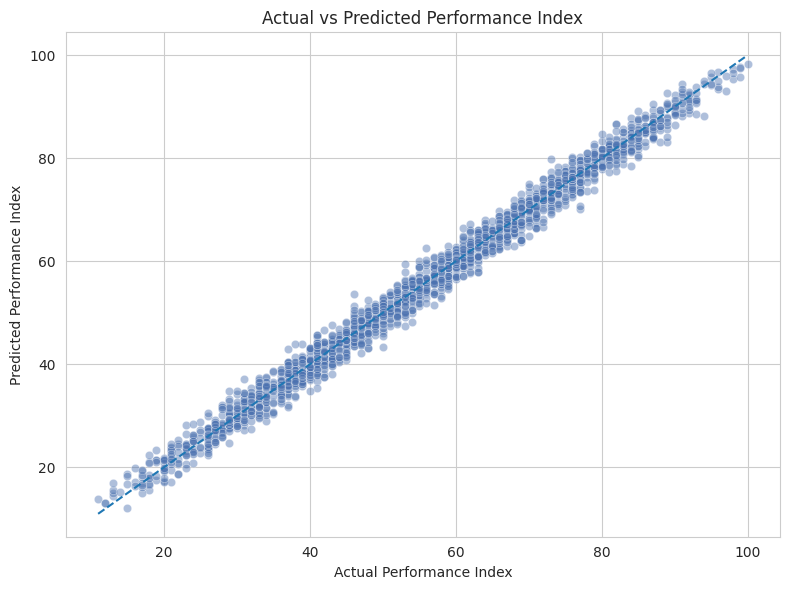

In [ ]:

# Visual validasi model: Actual vs Predicted
plt.figure(figsize=(8, 6))
sns.scatterplot(x=y_test, y=y_pred, alpha=0.45, color="#4C72B0")
min_val = min(y_test.min(), y_pred.min())
max_val = max(y_test.max(), y_pred.max())
plt.plot([min_val, max_val], [min_val, max_val], linestyle="--")
plt.title("Actual vs Predicted Performance Index")
plt.xlabel("Actual Performance Index")
plt.ylabel("Predicted Performance Index")
plt.tight_layout()

model_plot = os.path.join(OUTPUT_DIR, "06_actual_vs_predicted.png")
plt.savefig(model_plot, dpi=180, bbox_inches="tight")
plt.show()


In [ ]:

# Contoh prediksi beberapa siswa dari test set
prediction_sample = X_test.head(10).copy()
prediction_sample["Actual Performance Index"] = y_test.head(10).values
prediction_sample["Predicted Performance Index"] = model.predict(X_test.head(10)).round(2)
prediction_sample["Absolute Error"] = (
    prediction_sample["Actual Performance Index"] -
    prediction_sample["Predicted Performance Index"]
).abs().round(2)

display(prediction_sample)


### Interpretasi Model

R² menunjukkan proporsi variasi target yang dijelaskan model pada data uji; MAE dan RMSE menunjukkan besarnya kesalahan prediksi. Hasil evaluasi berlaku untuk pembagian data yang digunakan dan belum menjamin kinerja pada siswa atau periode lain.

Koefisien menggambarkan asosiasi setelah variabel lain diperhitungkan. Koefisien dan akurasi prediksi tidak membuktikan bahwa perubahan satu variabel akan menyebabkan perubahan nilai siswa.

Prediksi dapat membantu menyusun prioritas peninjauan, dengan keputusan intervensi tetap memerlukan pertimbangan pendidik.


## 9. Kesimpulan dan Rekomendasi

1. **Previous Scores** menunjukkan hubungan terkuat dengan Performance Index dan dapat digunakan untuk penyaringan awal.
2. **Hours Studied** menunjukkan hubungan positif di setiap kelompok nilai sebelumnya.
3. Kelompok nilai awal rendah dengan jam belajar rendah memiliki rata-rata performa paling rendah. Jam belajar tinggi pada kelompok nilai awal rendah masih belum menyamai rata-rata kelompok nilai awal menengah dengan jam belajar rendah.

**Usulan intervensi:**
- **Nilai awal rendah:** penguatan materi dasar dan pembinaan kebiasaan belajar.
- **Nilai awal menengah, jam belajar rendah:** dukungan jadwal dan konsistensi belajar.
- **Nilai awal tinggi, kebiasaan belajar baik:** pemantauan berkala.

Efektivitas program perlu diuji menggunakan data dari beberapa periode atau eksperimen sebelum diterapkan secara luas.
